In [30]:
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt

from scipy import signal as scipy_signal
from scipy.signal import butter, sosfiltfilt, welch

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True

pd.set_option("display.max_columns", None)

In [19]:
PROJECT_ROOT = Path("..")

METADATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "metadata"
    / "videos_alekpehanhou.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(METADATA_PATH, sep=";")

print(f"Nombre d'enregistrements : {len(df)}")
print(f"Dossier de sortie : {OUTPUT_DIR}")

Nombre d'enregistrements : 45
Dossier de sortie : ../data/processed


In [13]:
def load_audio(path):
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(f"Fichier introuvable : {path}")

    audio, sample_rate = sf.read(path)

    return {
        "audio": audio,
        "sample_rate": sample_rate,
        "channels": 1 if audio.ndim == 1 else audio.shape[1],
        "duration": len(audio) / sample_rate,
    }

In [22]:
selected_index = 9

selected_row = df.iloc[selected_index]
print(f"Enregistrement sélectionné : {selected_row['titre']}")

recording = load_audio(selected_row["chemin_audio"])

audio = recording["audio"]
sample_rate = recording["sample_rate"]

print("Titre :", selected_row["titre"])
print("Fréquence :", sample_rate)
print("Canaux :", recording["channels"])
print("Durée :", round(recording["duration"], 2), "secondes")
print("Dimensions :", audio.shape)

Enregistrement sélectionné : Jéjé Yi Koo ! (Hwèdè)
Titre : Jéjé Yi Koo ! (Hwèdè)
Fréquence : 44100
Canaux : 2
Durée : 346.44 secondes
Dimensions : (15278080, 2)


In [23]:
left_channel = audio[:, 0]
right_channel = audio[:, 1]

mono_signal = (left_channel + right_channel) / 2

print("Canal gauche :", left_channel.shape)
print("Canal droit :", right_channel.shape)
print("Signal mono :", mono_signal.shape)

Canal gauche : (15278080,)
Canal droit : (15278080,)
Signal mono : (15278080,)


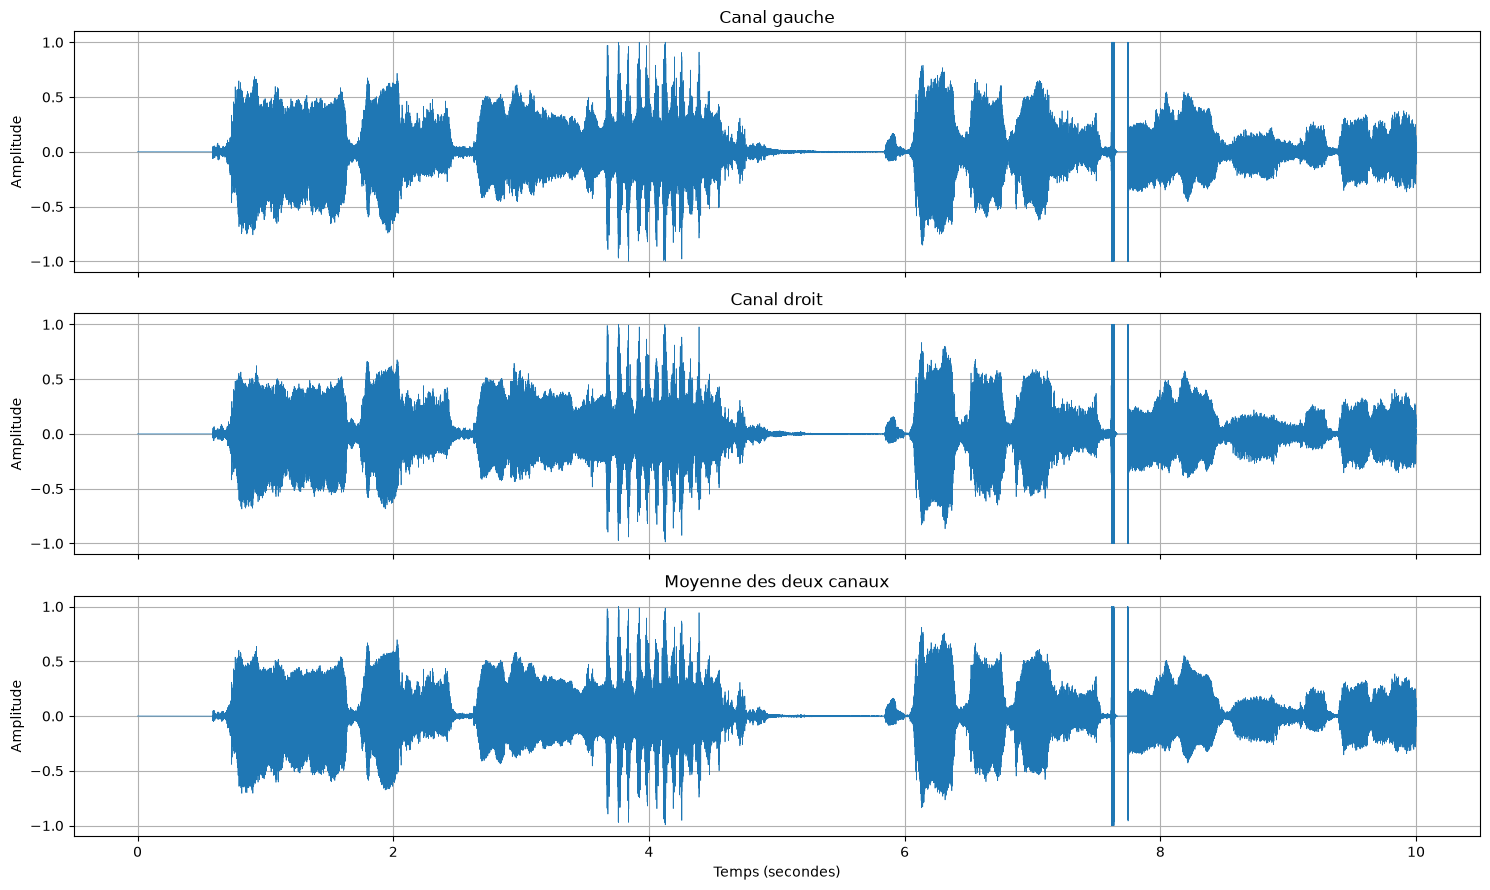

In [24]:
duration = 10
n_samples = int(duration * sample_rate)

time = np.arange(n_samples) / sample_rate

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)

signals = [
    (left_channel, "Canal gauche"),
    (right_channel, "Canal droit"),
    (mono_signal, "Moyenne des deux canaux")
]

for ax, (current_signal, title) in zip(axes, signals):
    ax.plot(
        time,
        current_signal[:n_samples],
        linewidth=0.5
    )

    ax.set_title(title)
    ax.set_ylabel("Amplitude")

axes[-1].set_xlabel("Temps (secondes)")

plt.tight_layout()
plt.show()

In [31]:
frequencies, psd = welch(
    mono_signal,
    fs=sample_rate,
    nperseg=8192,
    noverlap=4096
)

print("Nombre de fréquences :", len(frequencies))
print("Fréquence maximale :", frequencies.max())

Nombre de fréquences : 4097
Fréquence maximale : 22050.0


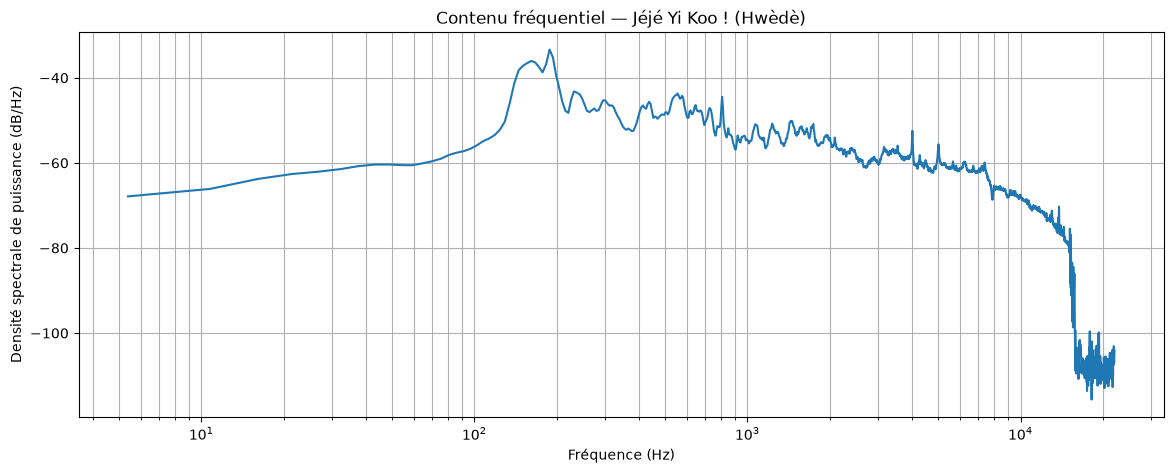

In [32]:
plt.figure(figsize=(14, 5))

plt.semilogx(
    frequencies[1:],
    10 * np.log10(psd[1:] + 1e-12)
)

plt.xlabel("Fréquence (Hz)")
plt.ylabel("Densité spectrale de puissance (dB/Hz)")
plt.title(f"Contenu fréquentiel — {selected_row['titre']}")

plt.grid(True, which="both")
plt.show()

In [33]:
frequency_bands = {
    "Basses fréquences": (20, 250),
    "Moyennes fréquences": (250, 2000),
    "Hautes fréquences": (2000, 10000)
}

band_results = []

for band_name, (low, high) in frequency_bands.items():

    mask = (frequencies >= low) & (frequencies < high)

    band_power = np.sum(psd[mask])

    band_results.append({
        "bande": band_name,
        "puissance": band_power
    })

band_df = pd.DataFrame(band_results)

band_df["proportion_percent"] = (
    band_df["puissance"]
    / band_df["puissance"].sum()
    * 100
)

display(band_df.round(2))

,bande,puissance,proportion_percent
0,Basses fréquences,0.0,41.52
1,Moyennes fréquences,0.0,40.38
2,Hautes fréquences,0.0,18.11


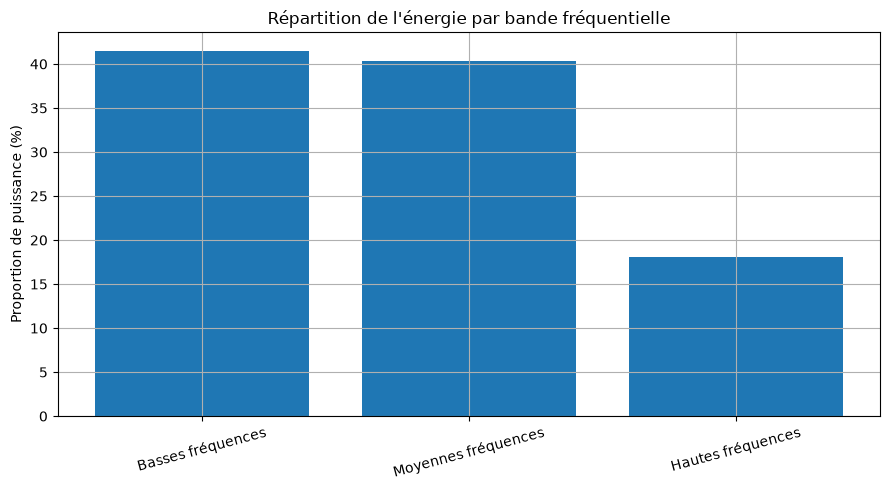

In [34]:
plt.figure(figsize=(9, 5))

plt.bar(
    band_df["bande"],
    band_df["proportion_percent"]
)

plt.ylabel("Proportion de puissance (%)")
plt.title("Répartition de l'énergie par bande fréquentielle")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [35]:
def bandpass_filter(audio, lowcut, highcut, sr, order=4):
    sos = butter(
        order,
        [lowcut, highcut],
        btype="bandpass",
        fs=sr,
        output="sos"
    )

    return sosfiltfilt(sos, audio)


low_band = bandpass_filter(
    mono_signal, 20, 250, sample_rate
)

mid_band = bandpass_filter(
    mono_signal, 250, 2000, sample_rate
)

high_band = bandpass_filter(
    mono_signal, 2000, 10000, sample_rate
)

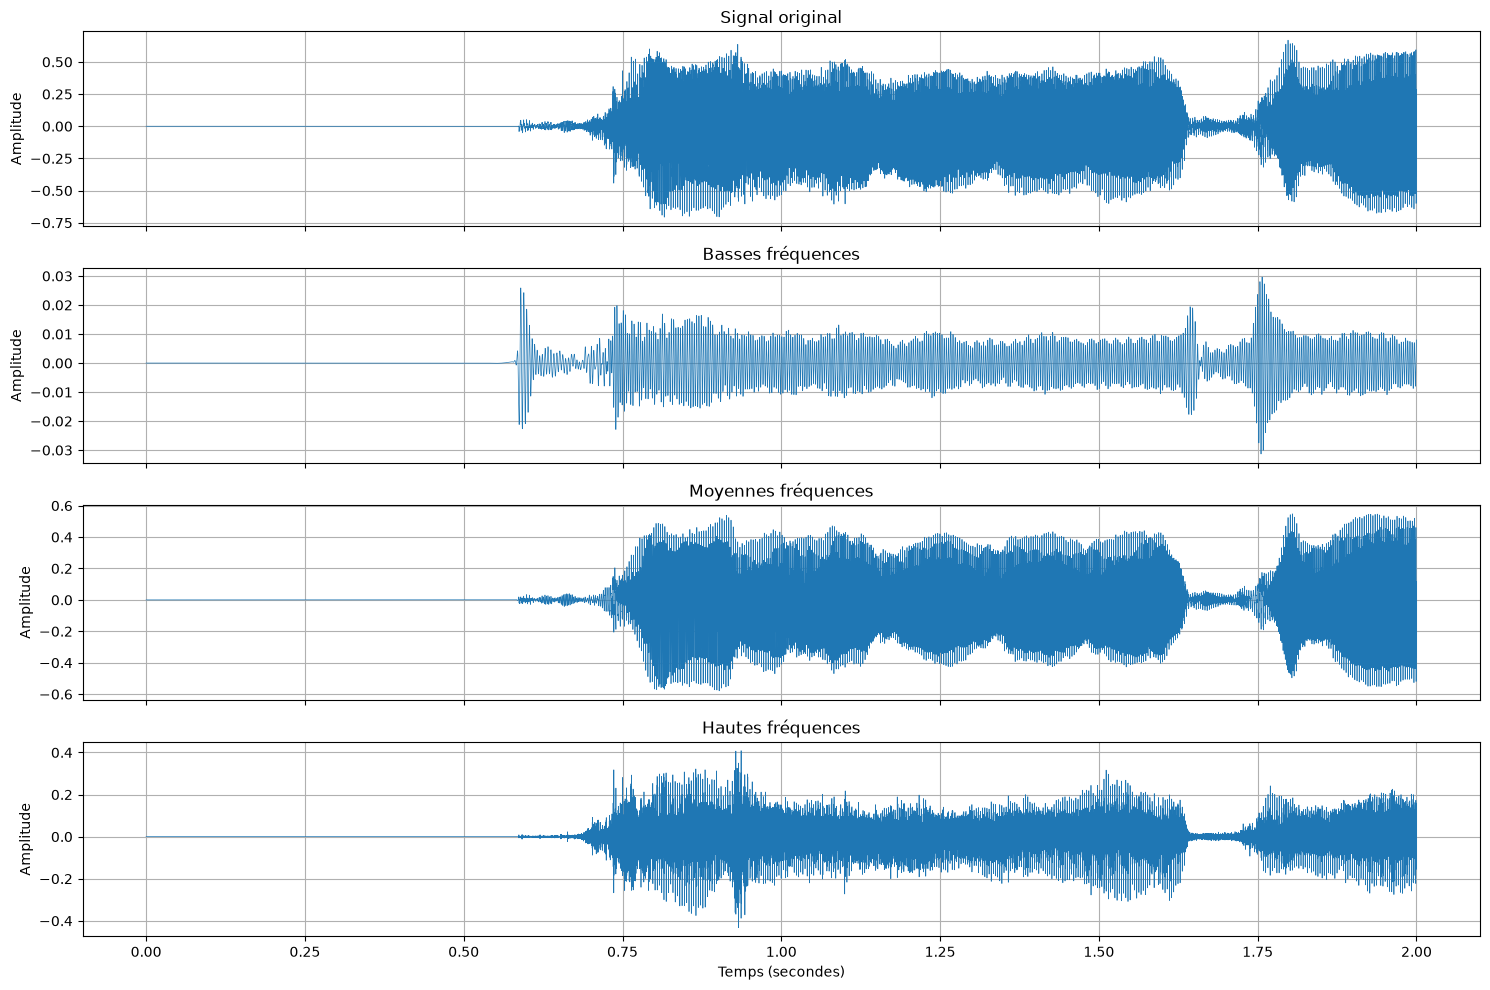

In [36]:
signals = [
    (mono_signal, "Signal original"),
    (low_band, "Basses fréquences"),
    (mid_band, "Moyennes fréquences"),
    (high_band, "Hautes fréquences")
]

duration = 2
n = int(duration * sample_rate)
time = np.arange(n) / sample_rate

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

for ax, (current_signal, title) in zip(axes, signals):
    ax.plot(time, current_signal[:n], linewidth=0.5)
    ax.set_title(title)
    ax.set_ylabel("Amplitude")

axes[-1].set_xlabel("Temps (secondes)")

plt.tight_layout()
plt.show()